# Decision Tree Classification using Iris Dataset

### Objective
Implement a simple **Decision Tree Classifier** using the Iris dataset and evaluate the model using:
- Accuracy
- Confusion Matrix
- Precision
- Recall
- F1-Score
- Classification Report

The notebook is designed for **Google Colab**.

image.png

In [ ]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Step 2: Load the Iris dataset

iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

print("Feature names:", feature_names)
print("Target names:", target_names)
print("Dataset shape:", X.shape)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
Dataset shape: (150, 4)


In [ ]:
# Step 3: Display the dataset

df = pd.DataFrame(X, columns=feature_names)
df["Target"] = y
df["Species"] = df["Target"].map(dict(enumerate(target_names)))

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [ ]:
# Step 4: Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


The Decision Tree calculates Entropy to measure impurity.
Entropy formula

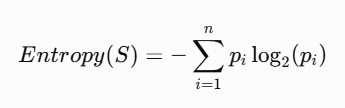
Then it calculates Information Gain:

Information\ Gain =
Entropy(parent)-Weighted\ Entropy(children)

The feature/split having the highest Information Gain is preferred for splitting the node.
For example, the tree may determine that petal length or petal width provides a very good split for separating the Iris classes.

In [ ]:
# Step 5: Create and train the Decision Tree model

model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Step 6: Make predictions

y_pred = model.predict(X_test)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)

Actual values:    [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [ ]:
# Step 7: Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Evaluation Metrics")
print("-------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Evaluation Metrics
-------------------
Accuracy  : 0.9667
Precision : 0.9697
Recall    : 0.9667
F1-Score  : 0.9666


In [ ]:
# Step 8: Classification Report

print(classification_report(
    y_test,
    y_pred,
    target_names=target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



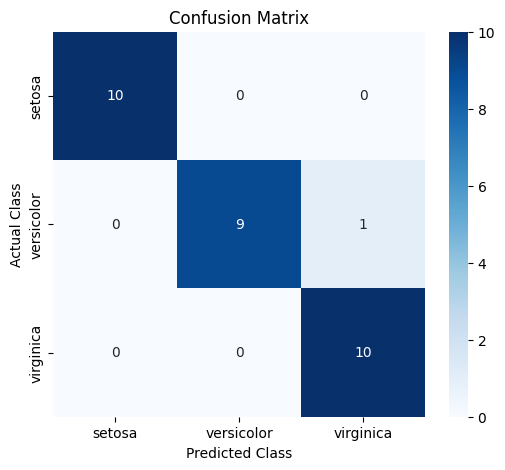

In [ ]:
# Step 9: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

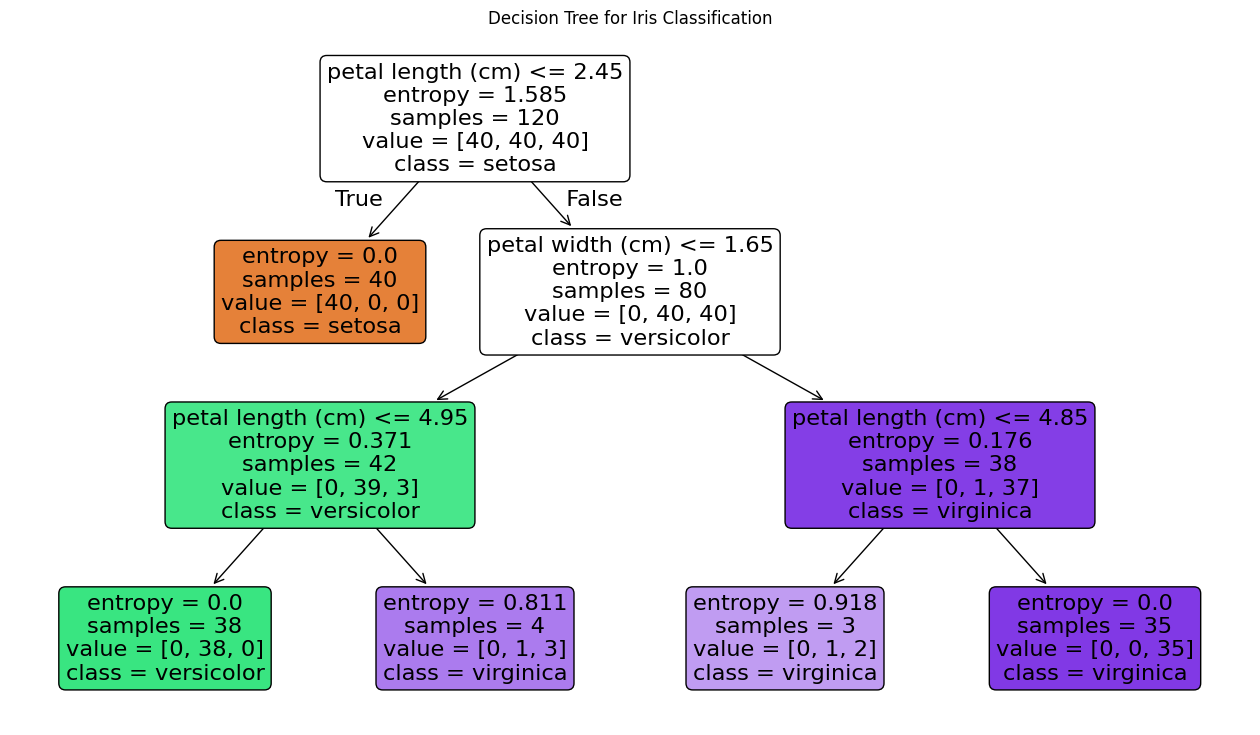

In [ ]:
# Step 10: Visualize the Decision Tree

plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Iris Classification")
plt.show()

             Feature  Importance
2  petal length (cm)    0.686546
3   petal width (cm)    0.313454
1   sepal width (cm)    0.000000
0  sepal length (cm)    0.000000


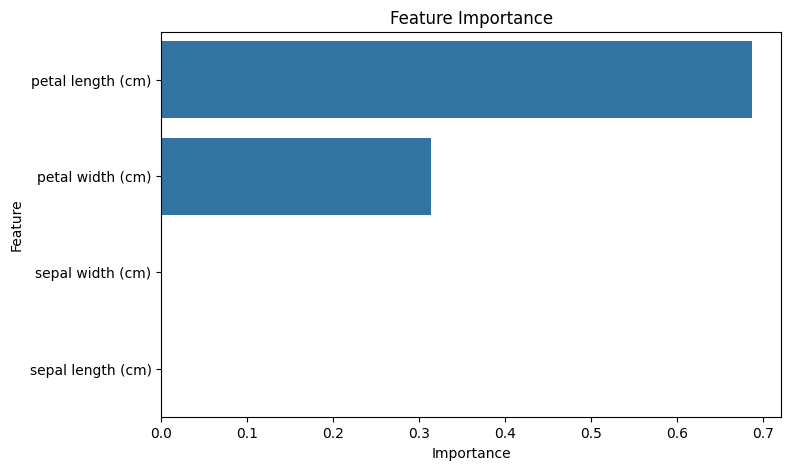

In [ ]:
# Step 11: Feature Importance

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## Conclusion

The Decision Tree successfully classifies the three Iris flower species:
- Setosa
- Versicolor
- Virginica

The model is evaluated using **Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and Classification Report**.

### Important parameters
- `criterion="gini"`: Uses Gini impurity to select splits.
- `max_depth=3`: Limits tree depth and helps keep the model simple.
- `random_state=42`: Makes the result reproducible.